<a href="https://colab.research.google.com/github/NatShed/SOTA_2026/blob/main/SOTA_17_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №17: Diffusion model с нуля и classifier-free guidance

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать forward noising и noise prediction.
- Обучить compact conditional network.
- Добавить CFG и сравнить guidance scales.

## Теоретическая часть

DDPM постепенно добавляет Gaussian noise, затем обучает network обращать процесс. Classifier-free guidance смешивает conditional и unconditional predictions и управляет компромиссом fidelity/diversity.

![DDPM](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/ddpm.png)


DDPM обучает εθ(x_t,t,y) восстанавливать внесённый шум. При classifier-free dropout условие заменяется специальным индексом 10; на inference ε_cfg=ε_u+w(ε_c−ε_u). Для MNIST качество класса проверяет отдельно обученный на train классификатор, его точность на test обязательно сообщается.

Прямой процесс: $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$. CFG: $\hat\epsilon=\epsilon_u+w(\epsilon_c-\epsilon_u)$; при двух вызовах сети на шаг $\mathrm{NFE}=2T$.

### Экспериментальный протокол

Данные MNIST: train первые 20 000, test первые 2 000, без пересечения. Полное обучение: 10 000 шагов; smoke: 2. Основной результат — реальные MNIST checkpoint и условная генерация при разных w. Для продолжения после сбоя сохраняйте artifacts в Drive или задайте CV_ARTIFACTS. Не смешивайте smoke/full checkpoint.

### Материалы

- [DDPM paper](https://arxiv.org/abs/2006.11239)
- [Annotated Diffusion](https://huggingface.co/blog/annotated-diffusion)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

Задача. Научиться генерировать картинки — в нашем случае рукописные цифры MNIST — с нуля.

Diffusion-модель — это генератор картинок, который работает так: берёт чистый шум и постепенно, шаг за шагом, «проявляет» из него цифру. Шагов обычно 1000. Каждый шаг — это один прогон нейросети.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [ ]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
from torchvision.utils import save_image, make_grid
import matplotlib.pyplot as plt
from collections import Counter

# Colab: plt.show() работает, %matplotlib inline не нужен
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True

SEED = 42
FAST_DEV_RUN = False   # <-- True для быстрой проверки. Для сдачи поставьте False и перезапустите.

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Безопасный путь к данным: в Colab cwd = /content, поэтому parents[1] не работает.
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', 'data'))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

def save_json(name, value):
    dest = ARTIFACTS / name
    dest.parent.mkdir(parents=True, exist_ok=True)
    dest.write_text(json.dumps(value, ensure_ascii=False, indent=2))

def save_fig(name, fig=None, dpi=120):
    if fig is None:
        fig = plt.gcf()
    path = ARTIFACTS / name
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=dpi, bbox_inches='tight')
    plt.show()
    plt.close(fig)

def to_imshow(t):
    """Принимает (B,C,H,W), (C,H,W) или (H,W) тензор и превращает в numpy для plt.imshow."""
    t = t.detach().cpu()
    # Снимаем батч, если он есть
    if t.dim() == 4:
        t = t[0]            # (B,C,H,W) -> (C,H,W)
    if t.dim() == 3:
        if t.shape[0] == 1:
            return t[0].numpy()          # (1,H,W) -> (H,W)
        return t.permute(1, 2, 0).numpy()  # (3,H,W) -> (H,W,3)
    return t.numpy()

print({'device': DEVICE,
       'fast_dev_run': FAST_DEV_RUN,
       'artifacts': str(ARTIFACTS.resolve()),
       'data_root': str(DATA_ROOT.resolve())})

{'device': 'cpu', 'fast_dev_run': False, 'artifacts': '/content/artifacts', 'data_root': '/content/data'}


### Расписание прямой диффузии

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума.

**Результат.** Проверяемое состояние «Расписание прямой диффузии» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума» и его результат доступен следующему этапу.

*Прямой процесс:* берём реальную цифру и постепенно добавляем шум.

Формула на каждом шаге: x_t = √ᾱ_t · x₀ + √(1−ᾱ_t) · ε, где ε ~ 𝒩(0, I) — гауссов шум, ᾱ_t — «сколько сигнала осталось» на шаге t.

При t=0: ᾱ₀ ≈ 1, x₀ — чистая цифра.

При t=T: ᾱ_T ≈ 0, x_T — чистый шум, от цифры не остаётся ничего.

*Обратный пероцесс:* учим нейросеть ε_θ(x_t, t, y) предсказывать тот шум, который был добавлен на шаге t. Зная шум, мы можем его вычесть и восстановить сигнал
x_{t-1} = (x_t − β_t/√(1−ᾱ_t) · ε_θ) / √α_t + шум

Если модель хорошо предсказывает ε, то итеративно восстановит x₀ из x_T.

x_t shape: (4, 1, 28, 28)
alphas_cumprod[0]   = 0.999900
alphas_cumprod[-1]  = 4.035830e-05


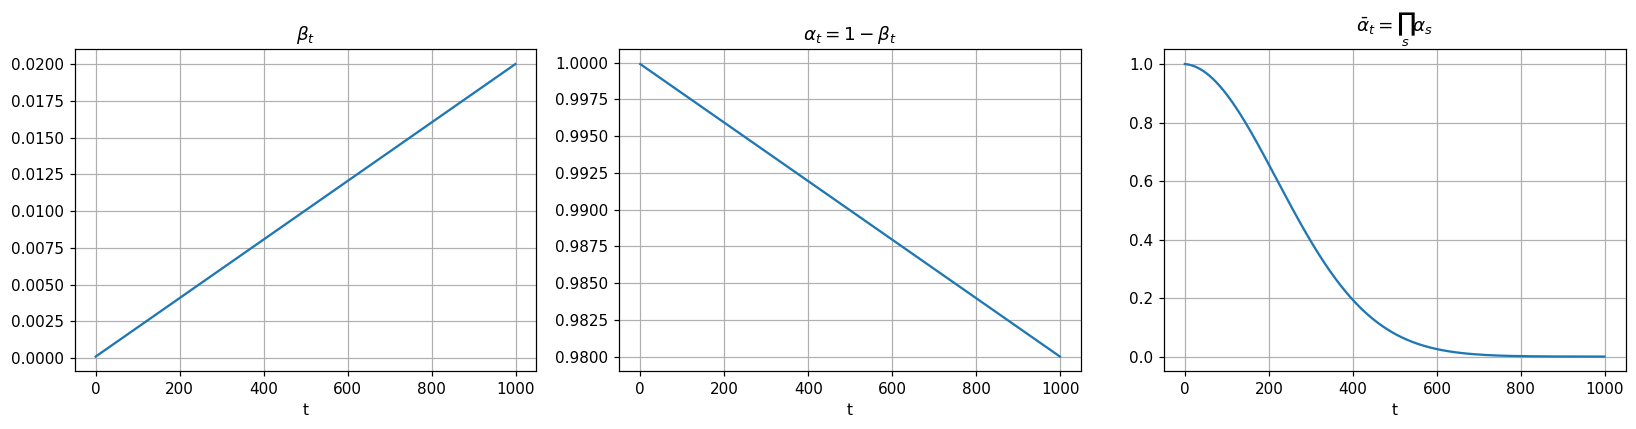

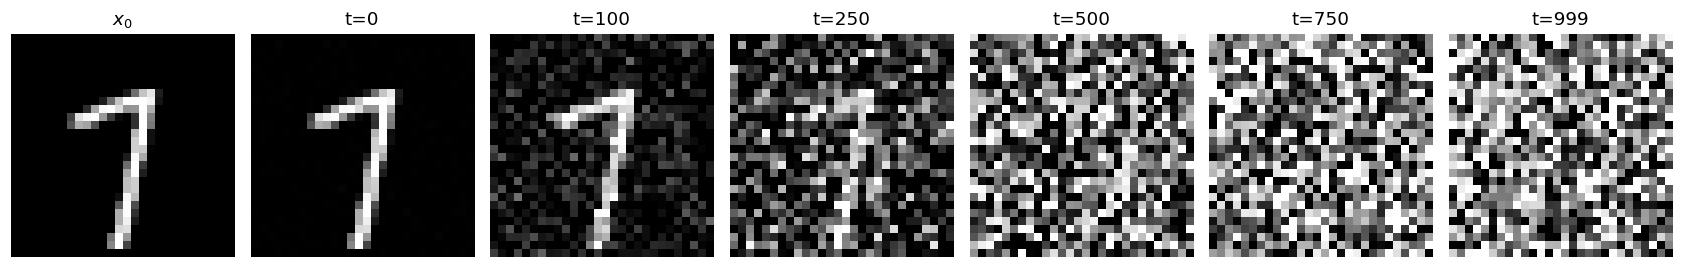

In [ ]:
T = 1000
beta_start, beta_end = 1e-4, 0.02

betas = torch.linspace(beta_start, beta_end, T).to(DEVICE)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

# Проверка формулы внесения шума
x0_test = torch.randn(4, 1, 28, 28, device=DEVICE) * 0.5 + 0.5
t_test  = torch.tensor([0, 250, 500, 999], device=DEVICE)
eps_test = torch.randn_like(x0_test)
sq_ac  = sqrt_alphas_cumprod[t_test].view(-1, 1, 1, 1)
sq_1mac = sqrt_one_minus_alphas_cumprod[t_test].view(-1, 1, 1, 1)
x_t_test = sq_ac * x0_test + sq_1mac * eps_test

print("x_t shape:", tuple(x_t_test.shape))
print(f"alphas_cumprod[0]   = {alphas_cumprod[0].item():.6f}")
print(f"alphas_cumprod[-1]  = {alphas_cumprod[-1].item():.6e}")

save_json("diffusion_schedule.json", {
    "T": T, "beta_start": beta_start, "beta_end": beta_end,
    "alphas_cumprod_first": alphas_cumprod[0].item(),
    "alphas_cumprod_last":  alphas_cumprod[-1].item(),
})

# --- Визуализация 1: кривые schedule ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(betas.cpu().numpy());          axes[0].set_title(r'$\beta_t$');          axes[0].set_xlabel('t')
axes[1].plot(alphas.cpu().numpy());         axes[1].set_title(r'$\alpha_t = 1-\beta_t$'); axes[1].set_xlabel('t')
axes[2].plot(alphas_cumprod.cpu().numpy()); axes[2].set_title(r'$\bar\alpha_t = \prod_s \alpha_s$'); axes[2].set_xlabel('t')
plt.tight_layout(); save_fig('schedule_curves.png')

# --- Визуализация 2: зашумление одной цифры ---
_demo = torchvision.datasets.MNIST(root=DATA_ROOT, train=True, download=True,
                                    transform=transforms.ToTensor())
x_demo = (_demo[42][0] * 2 - 1).unsqueeze(0).to(DEVICE)

t_demo_vals = [0, 100, 250, 500, 750, 999]
fig, axes = plt.subplots(1, len(t_demo_vals) + 1, figsize=(2.2 * (len(t_demo_vals) + 1), 2.6))
axes[0].imshow(to_imshow(x_demo), cmap='gray', vmin=-1, vmax=1); axes[0].set_title(r'$x_0$'); axes[0].axis('off')
for i, tv in enumerate(t_demo_vals, start=1):
    e = torch.randn_like(x_demo)
    xt = sqrt_alphas_cumprod[tv] * x_demo + sqrt_one_minus_alphas_cumprod[tv] * e
    axes[i].imshow(to_imshow(xt), cmap='gray', vmin=-1, vmax=1)
    axes[i].set_title(f't={tv}'); axes[i].axis('off')
plt.tight_layout(); save_fig('forward_noising_demo.png')

### Условный denoiser и проверка форм

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода.

**Результат.** Проверяемое состояние «Условный denoiser и проверка форм» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода» и его результат доступен следующему этапу.

input: (2, 1, 28, 28)  output: (2, 1, 28, 28)


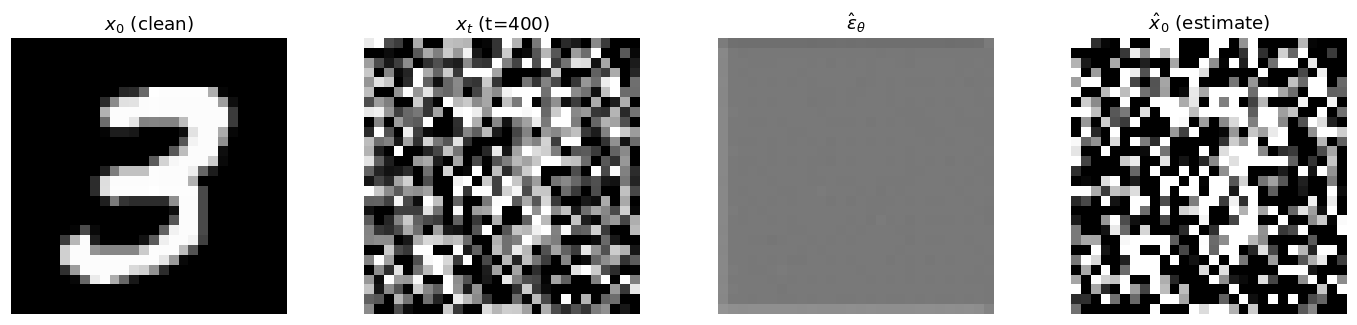

In [ ]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, time):
        half = self.dim // 2
        emb = torch.log(torch.tensor(10000.0, device=time.device)) / (half - 1)
        emb = torch.exp(torch.arange(half, device=time.device) * -emb)
        emb = time[:, None] * emb[None, :]
        return torch.cat((emb.sin(), emb.cos()), dim=-1)

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, t_dim, n_cls=11):
        super().__init__()
        self.time_mlp  = nn.Linear(t_dim, out_ch)
        self.class_emb = nn.Embedding(n_cls, out_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.bn1   = nn.BatchNorm2d(out_ch)
        self.bn2   = nn.BatchNorm2d(out_ch)
        self.act   = nn.SiLU()
    def forward(self, x, t_emb, y):
        h = self.act(self.bn1(self.conv1(x)))
        h = h + self.time_mlp(t_emb)[:, :, None, None] + self.class_emb(y)[:, :, None, None]
        h = self.act(self.bn2(self.conv2(h)))
        return h

class SimpleUNet(nn.Module):
    def __init__(self, in_ch=1, base=64, t_dim=128, n_cls=11):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(t_dim),
            nn.Linear(t_dim, t_dim), nn.ReLU())
        self.d1 = ConvBlock(in_ch, base,     t_dim, n_cls)
        self.p1 = nn.MaxPool2d(2)
        self.d2 = ConvBlock(base, base * 2, t_dim, n_cls)
        self.p2 = nn.MaxPool2d(2)
        self.mid = ConvBlock(base * 2, base * 2, t_dim, n_cls)
        self.u1  = nn.ConvTranspose2d(base * 2, base * 2, 2, stride=2)
        self.cu1 = ConvBlock(base * 4, base, t_dim, n_cls)
        self.u2  = nn.ConvTranspose2d(base, base, 2, stride=2)
        self.cu2 = ConvBlock(base * 2, base, t_dim, n_cls)
        self.out = nn.Conv2d(base, in_ch, 1)
    def forward(self, x, t, y):
        te = self.time_mlp(t)
        d1 = self.d1(x, te, y)
        d2 = self.d2(self.p1(d1), te, y)
        m  = self.mid(self.p2(d2), te, y)
        u1 = self.cu1(torch.cat([self.u1(m), d2], 1), te, y)
        u2 = self.cu2(torch.cat([self.u2(u1), d1], 1), te, y)
        return self.out(u2)

model = SimpleUNet().to(DEVICE)
x_dummy = torch.randn(2, 1, 28, 28, device=DEVICE)
t_dummy = torch.randint(0, T, (2,), device=DEVICE)
y_dummy = torch.tensor([3, 7], device=DEVICE)
out_dummy = model(x_dummy, t_dummy, y_dummy)
print("input:", tuple(x_dummy.shape), " output:", tuple(out_dummy.shape))
assert out_dummy.shape == x_dummy.shape
save_json("denoiser_shape_check.json",
          {"input_shape": list(x_dummy.shape), "output_shape": list(out_dummy.shape)})

# --- Визуализация прямого прохода ---
model.eval()
with torch.no_grad():
    x0_vis = (_demo[7][0] * 2 - 1).unsqueeze(0).to(DEVICE)
    t_vis  = 400
    e_vis  = torch.randn_like(x0_vis)
    x_t_vis = sqrt_alphas_cumprod[t_vis] * x0_vis + sqrt_one_minus_alphas_cumprod[t_vis] * e_vis
    y_vis   = torch.tensor([7], device=DEVICE)
    pred_e  = model(x_t_vis, torch.tensor([t_vis], device=DEVICE), y_vis)
    x0_hat  = ((x_t_vis - sqrt_one_minus_alphas_cumprod[t_vis] * pred_e)
               / sqrt_alphas_cumprod[t_vis]).clamp(-1, 1)

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, (img, title) in zip(axes, [
    (x0_vis,  r'$x_0$ (clean)'),
    (x_t_vis, f'$x_t$ (t={t_vis})'),
    (pred_e,  r'$\hat\epsilon_\theta$'),
    (x0_hat,  r'$\hat x_0$ (estimate)')]):
    ax.imshow(to_imshow(img), cmap='gray', vmin=-1, vmax=1); ax.set_title(title); ax.axis('off')
plt.tight_layout(); save_fig('denoiser_forward_demo.png')

### Train/test MNIST для DDPM

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите фиксированный непересекающийся split и DataLoader.

**Результат.** Проверяемое состояние «Train/test MNIST для DDPM» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите фиксированный непересекающийся split и DataLoader» и его результат доступен следующему этапу.

Train size: 20000, Test size: 2000


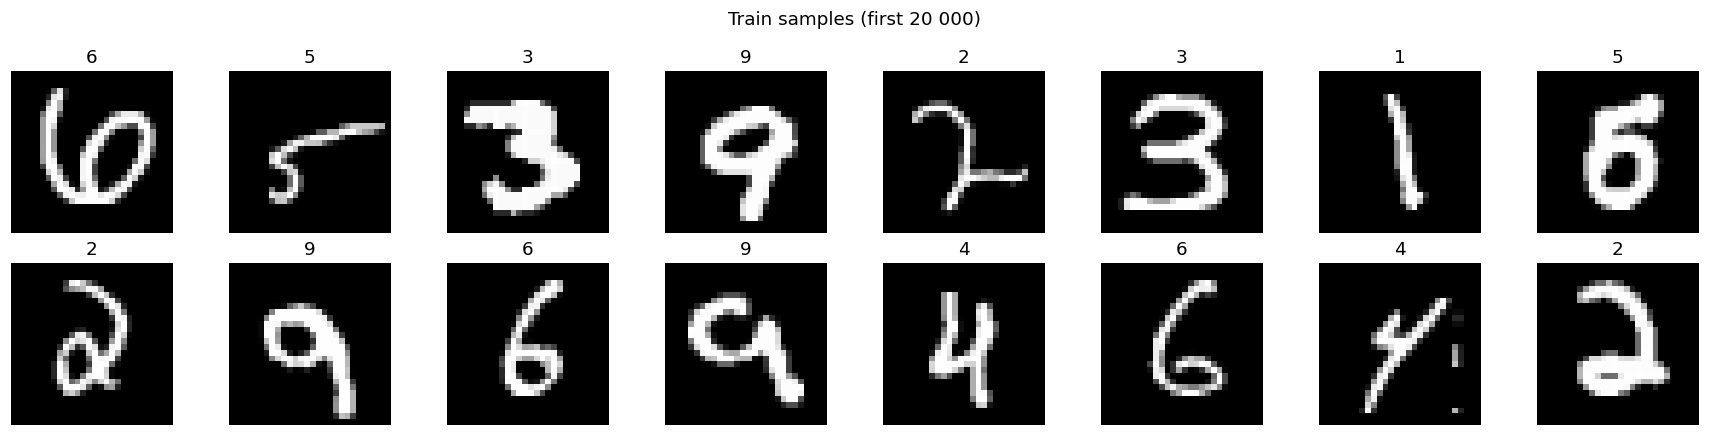

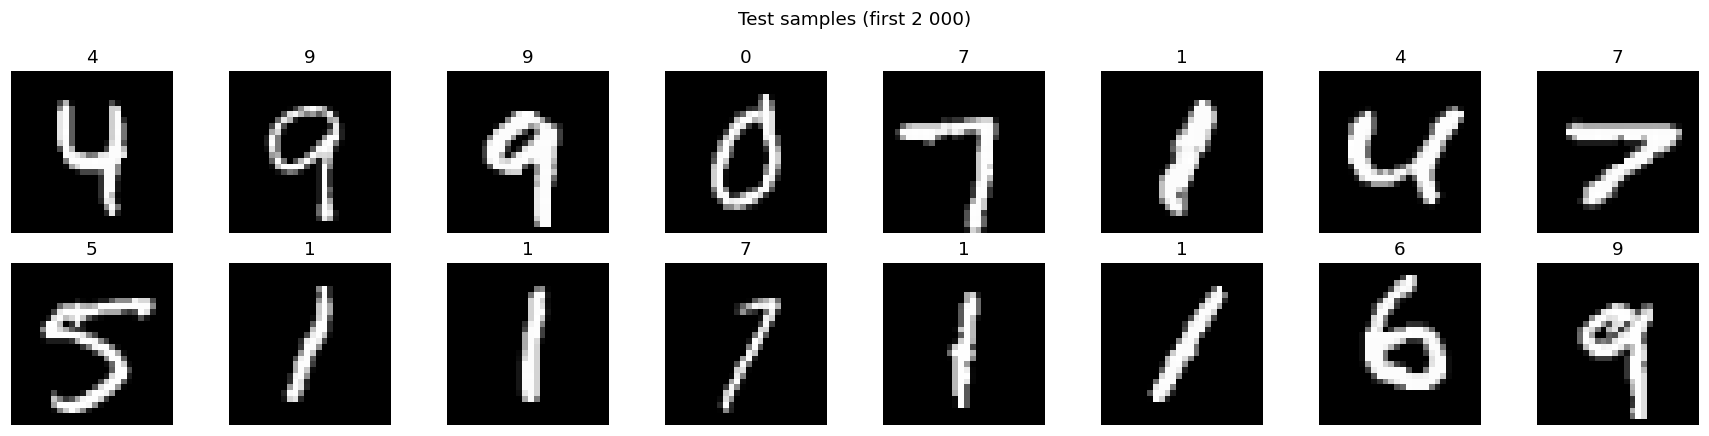

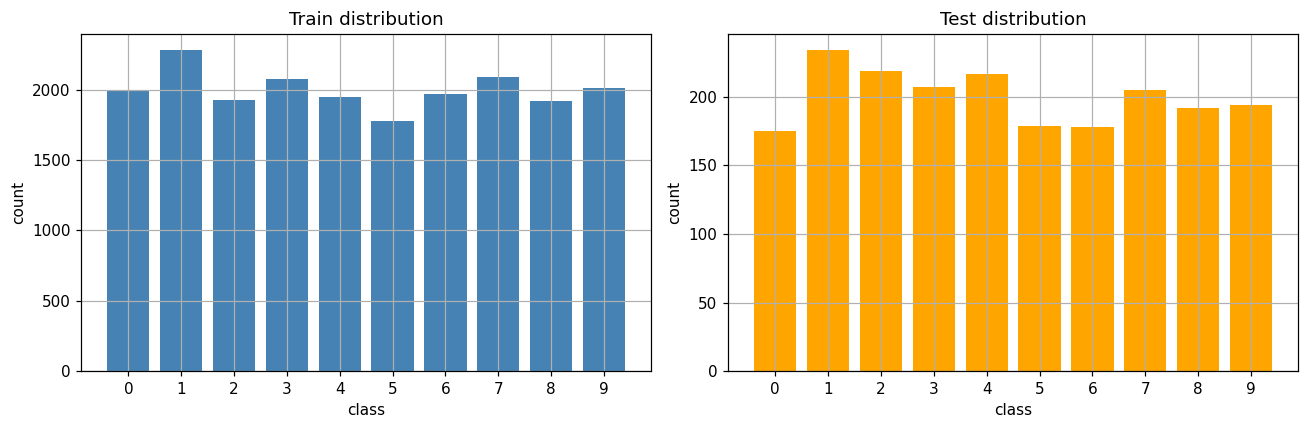

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))   # в [-1, 1]
])

train_full = torchvision.datasets.MNIST(root=DATA_ROOT, train=True,  download=True, transform=transform)
test_full  = torchvision.datasets.MNIST(root=DATA_ROOT, train=False, download=True, transform=transform)

# Берём первые 20 000 из train и первые 2 000 из test; это разные split'ы -> пересечения данных нет.
train_indices = list(range(20000))
test_indices  = list(range(2000))
assert train_full is not test_full

train_dataset = Subset(train_full, train_indices)
test_dataset  = Subset(test_full,  test_indices)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train size: {len(train_dataset)}, Test size: {len(test_dataset)}")

# --- Визуализация: примеры и распределение ---
def _show_samples(ds, n, title, fname):
    fig, axes = plt.subplots(2, n // 2, figsize=(n, 4))
    idxs = torch.randperm(len(ds), generator=torch.Generator().manual_seed(SEED))[:n]
    for ax, i in zip(axes.flat, idxs):
        img, lbl = ds[int(i)]
        ax.imshow(to_imshow(img), cmap='gray', vmin=-1, vmax=1)
        ax.set_title(str(lbl)); ax.axis('off')
    plt.suptitle(title)
    plt.tight_layout(); save_fig(fname)

_show_samples(train_dataset, 16, 'Train samples (first 20 000)', 'train_samples.png')
_show_samples(test_dataset,  16, 'Test samples (first 2 000)',   'test_samples.png')

tr_labels = [train_full[i][1] for i in train_indices]
te_labels = [test_full[i][1]  for i in test_indices]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, labels, color, title in [
    (axes[0], tr_labels, 'steelblue', 'Train distribution'),
    (axes[1], te_labels, 'orange',    'Test distribution')]:
    cnt = Counter(labels)
    ax.bar(range(10), [cnt.get(k, 0) for k in range(10)], color=color)
    ax.set_xticks(range(10)); ax.set_title(title); ax.set_xlabel('class'); ax.set_ylabel('count')
plt.tight_layout(); save_fig('class_distribution.png')

### Обучение epsilon-предсказателя с CFG dropout

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора.

**Результат.** Проверяемое состояние «Обучение epsilon-предсказателя с CFG dropout» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора» и его результат доступен следующему этапу.

Обычная модель выдаёт «любой шум». CFG делает так, чтобы модель следовала классу y.

Приём: при обучении с вероятностью 10–15% заменяем метку на «пустой» класс ∅ = 10. Тогда модель учится двум режимам одновременно:

ε_θ(x_t, t, y) — условный (знает, какую цифру генерирует);

ε_θ(x_t, t, ∅) — безусловный (не знает)

Учим модель предсказывать шум.

Loss = MSE между истинным и предсказанным шумом.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch 1/10  loss=0.1746
Epoch 2/10  loss=0.0630
Epoch 3/10  loss=0.0529
Epoch 4/10  loss=0.0468
Epoch 5/10  loss=0.0435
Epoch 6/10  loss=0.0407
Epoch 7/10  loss=0.0391
Epoch 8/10  loss=0.0372
Epoch 9/10  loss=0.0359
Epoch 10/10  loss=0.0353


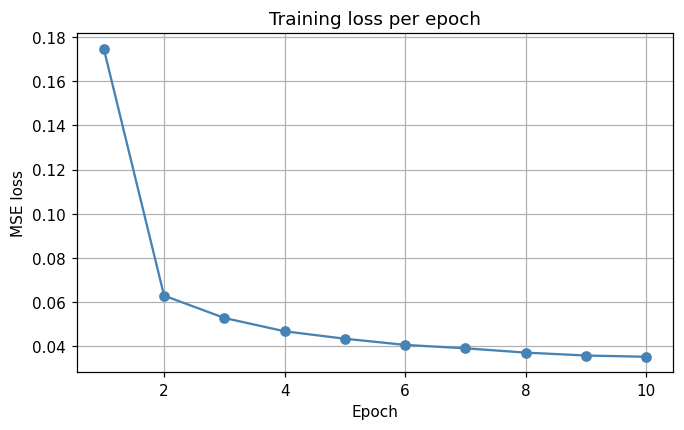

In [ ]:
P_DROP = 0.15
EPOCHS = 10 if not FAST_DEV_RUN else 1
LR     = 2e-4
CKPT_PATH = ARTIFACTS / ("ddpm_checkpoint_smoke.pt" if FAST_DEV_RUN else "ddpm_checkpoint.pt")

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
mse_loss  = nn.MSELoss()

def train_step(x0, y):
    x0, y = x0.to(DEVICE), y.to(DEVICE)
    bs = x0.size(0)
    drop = torch.rand(bs, device=DEVICE) < P_DROP
    y_cond = y.clone(); y_cond[drop] = 10
    t = torch.randint(0, T, (bs,), device=DEVICE)
    noise = torch.randn_like(x0)
    xt = sqrt_alphas_cumprod[t].view(-1,1,1,1) * x0 \
       + sqrt_one_minus_alphas_cumprod[t].view(-1,1,1,1) * noise
    return mse_loss(model(xt, t, y_cond), noise)

# Загрузка checkpoint
start_epoch, epoch_losses = 0, []
if not FAST_DEV_RUN and CKPT_PATH.exists():
    ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state"])
    optimizer.load_state_dict(ckpt["optimizer_state"])
    start_epoch = ckpt.get("epoch", 0)
    epoch_losses = ckpt.get("epoch_losses", [])
    print(f"Возобновление с эпохи {start_epoch}")

max_steps = 2 if FAST_DEV_RUN else None
global_step = 0

for epoch in range(start_epoch, EPOCHS):
    model.train()
    total_loss, seen = 0.0, 0
    for x0, y in train_loader:
        optimizer.zero_grad()
        loss = train_step(x0, y)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * x0.size(0); seen += x0.size(0)
        global_step += 1
        if max_steps is not None and global_step >= max_steps:
            break
    avg = total_loss / seen if seen else float('nan')
    epoch_losses.append(avg)
    print(f"Epoch {epoch+1}/{EPOCHS}  loss={avg:.4f}")
    if max_steps is not None and global_step >= max_steps:
        print("[SMOKE] Останавливаюсь после 2 шагов."); break

torch.save({
    "model_state": model.state_dict(),
    "optimizer_state": optimizer.state_dict(),
    "epoch": EPOCHS if not FAST_DEV_RUN else 1,
    "epoch_losses": epoch_losses,
}, CKPT_PATH)
save_json("training_metrics.json", {"epochs": len(epoch_losses), "epoch_losses": epoch_losses})

# --- Визуализация: кривая loss ---
if epoch_losses:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(1, len(epoch_losses) + 1), epoch_losses, marker='o', color='steelblue')
    ax.set_xlabel('Epoch'); ax.set_ylabel('MSE loss')
    ax.set_title('Training loss per epoch')
    save_fig('training_loss_curve.png')

Loss падает с ~0.17
 до ~0.03 за 10 эпох. Модель обучена.



### Независимый классификатор для оценки

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите только на train и измерьте точность классификатора на real test.

**Результат.** Проверяемое состояние «Независимый классификатор для оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите только на train и измерьте точность классификатора на real test» и его результат доступен следующему этапу.

Обучаем отдельный CNN-классификатор на train MNIST. Он не участвует в генерации — только оценивает сгенерированные картинки.

Classifier epoch 1: loss=0.5228
Classifier epoch 2: loss=0.1305
Classifier epoch 3: loss=0.0883
Classifier epoch 4: loss=0.0610
Classifier epoch 5: loss=0.0507
Classifier accuracy on real test: 0.9820


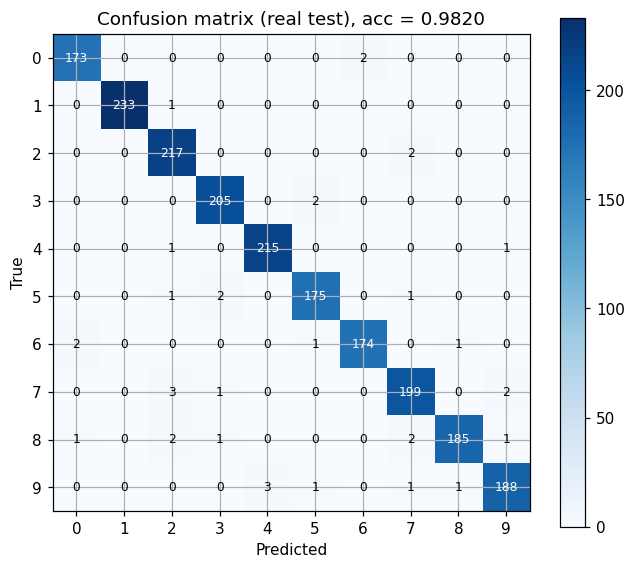

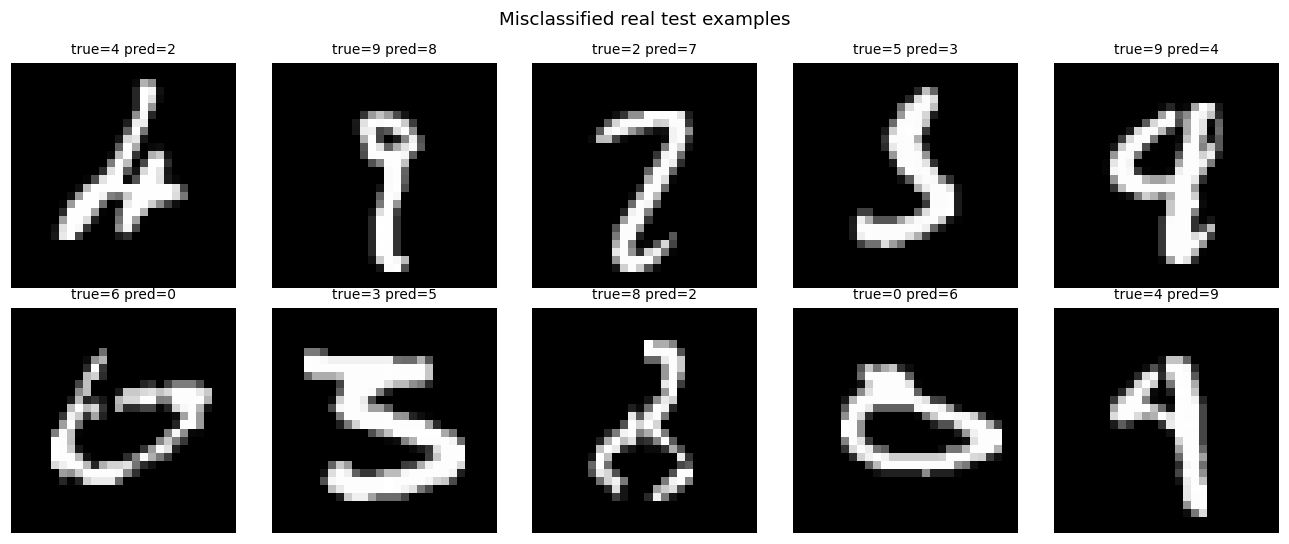

In [ ]:
class SimpleClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool  = nn.MaxPool2d(2)
        self.fc1   = nn.Linear(64*7*7, 128)
        self.fc2   = nn.Linear(128, 10)
        self.dropout = nn.Dropout(0.25)
    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        return self.fc2(x)

CLF_PATH = ARTIFACTS / "classifier.pt"
clf = SimpleClassifier().to(DEVICE)
clf_opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
clf_crit = nn.CrossEntropyLoss()

if CLF_PATH.exists():
    clf.load_state_dict(torch.load(CLF_PATH, map_location=DEVICE))
    print("Классификатор загружен из checkpoint.")
else:
    clf_epochs = 1 if FAST_DEV_RUN else 5
    max_batches = 2 if FAST_DEV_RUN else None
    for ep in range(clf_epochs):
        clf.train(); total, seen = 0.0, 0
        for i, (x, y) in enumerate(train_loader):
            x, y = x.to(DEVICE), y.to(DEVICE)
            clf_opt.zero_grad()
            loss = clf_crit(clf(x), y)
            loss.backward(); clf_opt.step()
            total += loss.item() * x.size(0); seen += x.size(0)
            if max_batches is not None and i + 1 >= max_batches: break
        print(f"Classifier epoch {ep+1}: loss={total/seen:.4f}")
    torch.save(clf.state_dict(), CLF_PATH)

# Точность на real test
clf.eval()
all_preds, all_labels, all_imgs = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        logits = clf(x.to(DEVICE))
        all_preds.append(logits.argmax(1).cpu())
        all_labels.append(y); all_imgs.append(x)
all_preds  = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()
all_imgs   = torch.cat(all_imgs)
test_acc   = float((all_preds == all_labels).mean())
print(f"Classifier accuracy on real test: {test_acc:.4f}")
save_json("classifier_accuracy.json", {"real_test_accuracy": test_acc})

# --- Визуализация: confusion matrix ---
cm = np.zeros((10, 10), dtype=int)
for t, p in zip(all_labels, all_preds):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title(f'Confusion matrix (real test), acc = {test_acc:.4f}')
thr = cm.max() / 2
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > thr else 'black')
plt.colorbar(im); save_fig('classifier_confusion_matrix.png')

# --- Визуализация: 10 ошибок классификатора ---
wrong = np.where(all_preds != all_labels)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, wrong):
    ax.imshow(to_imshow(all_imgs[idx]), cmap='gray', vmin=-1, vmax=1)
    ax.set_title(f'true={all_labels[idx]} pred={all_preds[idx]}', fontsize=9); ax.axis('off')
plt.suptitle('Misclassified real test examples')
plt.tight_layout(); save_fig('classifier_misclassified.png')

### Сбалансированные классы и общий шум

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG.

**Результат.** Проверяемое состояние «Сбалансированные классы и общий шум» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG» и его результат доступен следующему этапу.

x_init: (100, 1, 28, 28)  метки: {0: 10, 1: 10, 2: 10, 3: 10, 4: 10, 5: 10, 6: 10, 7: 10, 8: 10, 9: 10}


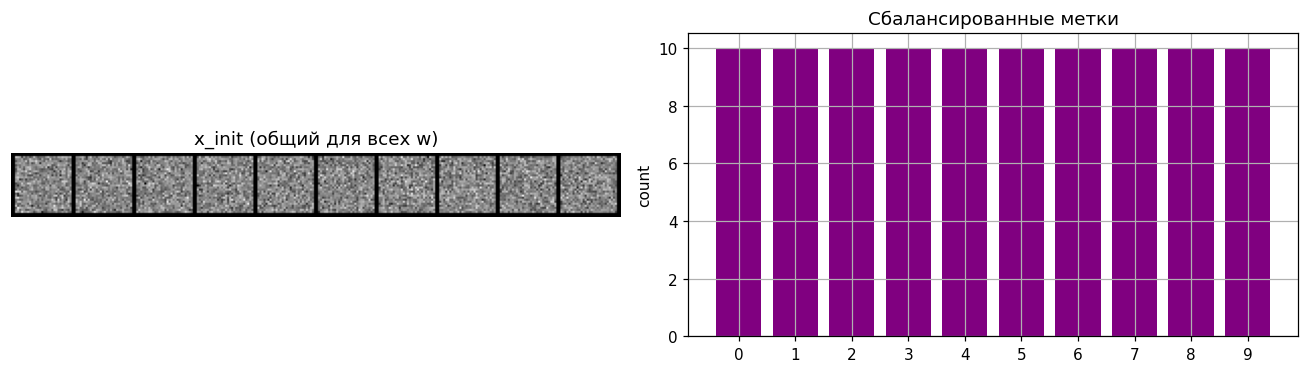

In [ ]:
NUM_SAMPLES_PER_CLASS = 3 if FAST_DEV_RUN else 10
TOTAL_SAMPLES = NUM_SAMPLES_PER_CLASS * 10

gen = torch.Generator(device=DEVICE).manual_seed(SEED)
x_init = torch.randn(TOTAL_SAMPLES, 1, 28, 28, generator=gen, device=DEVICE)
labels = torch.arange(10).repeat_interleave(NUM_SAMPLES_PER_CLASS).to(DEVICE)

print("x_init:", tuple(x_init.shape),
      " метки:", dict(Counter(labels.cpu().tolist())))

torch.save({"x_init": x_init.cpu(), "labels": labels.cpu()},
           ARTIFACTS / "initial_noise_and_labels.pt")

# --- Визуализация ---
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
g = make_grid(x_init[:10].cpu(), nrow=10, normalize=True)
axes[0].imshow(to_imshow(g.squeeze(0)), cmap='gray')
axes[0].set_title('x_init (общий для всех w)'); axes[0].axis('off')

cnt = Counter(labels.cpu().tolist())
axes[1].bar(range(10), [cnt.get(k, 0) for k in range(10)], color='purple')
axes[1].set_xticks(range(10)); axes[1].set_title('Сбалансированные метки'); axes[1].set_ylabel('count')
plt.tight_layout(); save_fig('shared_noise_and_labels.png')

### DDPM sampling и guidance

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE.

**Результат.** Проверяемое состояние «DDPM sampling и guidance» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE» и его результат доступен следующему этапу.

Sampling w = 0.0 ...
Sampling w = 1.0 ...
Sampling w = 3.0 ...
Sampling w = 5.0 ...
Sampling w = 7.0 ...
Sampling w = 10.0 ...
Готово. NFE на шаг: w∈{0,1} → 1; иначе → 2.


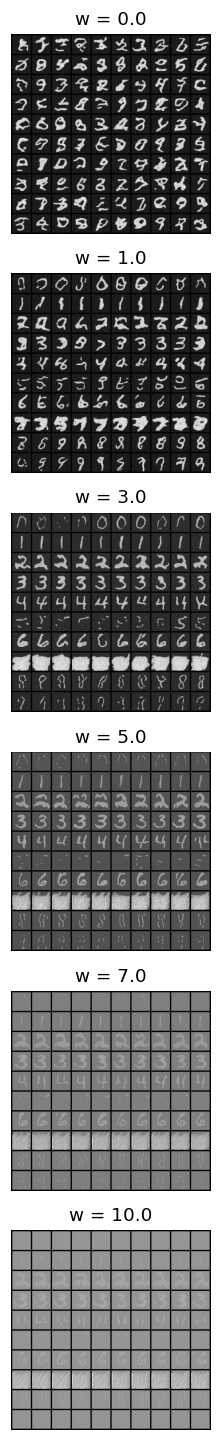

In [ ]:
@torch.no_grad()
def sample_ddpm(model, x_init, labels, w=1.0, T=T, device=DEVICE):
    """w=1 -> условная (1 NFE); w=0 -> безусловная (1 NFE); иначе CFG (2 NFE)."""
    model.eval()
    x = x_init.clone()
    bs = x.size(0)
    y_uncond = torch.full_like(labels, 10)
    for t_step in reversed(range(T)):
        t = torch.full((bs,), t_step, device=device, dtype=torch.long)
        if w == 0.0:
            pred = model(x, t, y_uncond)
        elif w == 1.0:
            pred = model(x, t, labels)
        else:
            x2 = torch.cat([x, x], 0); t2 = torch.cat([t, t], 0)
            y2 = torch.cat([labels, y_uncond], 0)
            both = model(x2, t2, y2)
            eps_c, eps_u = both[:bs], both[bs:]
            pred = eps_u + w * (eps_c - eps_u)
        beta_t      = betas[t_step]
        alpha_t     = alphas[t_step]
        alpha_bar_t = alphas_cumprod[t_step]
        mean = (1.0 / torch.sqrt(alpha_t)) * (
            x - (beta_t / torch.sqrt(1.0 - alpha_bar_t)) * pred)
        if t_step > 0:
            x = mean + torch.sqrt(beta_t) * torch.randn_like(x)
        else:
            x = mean
    return x

guidance_scales = [1.0, 3.0] if FAST_DEV_RUN else [0.0, 1.0, 3.0, 5.0, 7.0, 10.0]
generated_images = {}

for w in guidance_scales:
    print(f"Sampling w = {w} ...")
    imgs = sample_ddpm(model, x_init, labels, w=w).cpu()
    generated_images[w] = imgs
    grid = make_grid(imgs, nrow=NUM_SAMPLES_PER_CLASS, normalize=True)
    save_image(grid, ARTIFACTS / f"generated_w{w}.png")

torch.save(generated_images, ARTIFACTS / "generated_images.pt")
print("Готово. NFE на шаг: w∈{0,1} → 1; иначе → 2.")

# --- Визуализация: сетки для всех w ---
n_w = len(guidance_scales)
fig, axes = plt.subplots(n_w, 1, figsize=(14, 2.2 * n_w))
if n_w == 1: axes = [axes]
for ax, w in zip(axes, guidance_scales):
    grid = make_grid(generated_images[w], nrow=NUM_SAMPLES_PER_CLASS, normalize=True)
    ax.imshow(to_imshow(grid), cmap='gray')
    ax.set_title(f'w = {w}'); ax.axis('off')
plt.tight_layout(); save_fig('guidance_comparison.png')

### Сохранение измерений генерации

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните метрики, изображения и точность проверяющего классификатора на test.

**Результат.** Проверяемое состояние «Сохранение измерений генерации» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните метрики, изображения и точность проверяющего классификатора на test» и его результат доступен следующему этапу.

w = 0.0: classifier acc on generated = 0.0700
w = 1.0: classifier acc on generated = 0.6700
w = 3.0: classifier acc on generated = 0.8100
w = 5.0: classifier acc on generated = 0.6900
w = 7.0: classifier acc on generated = 0.6200
w = 10.0: classifier acc on generated = 0.5900


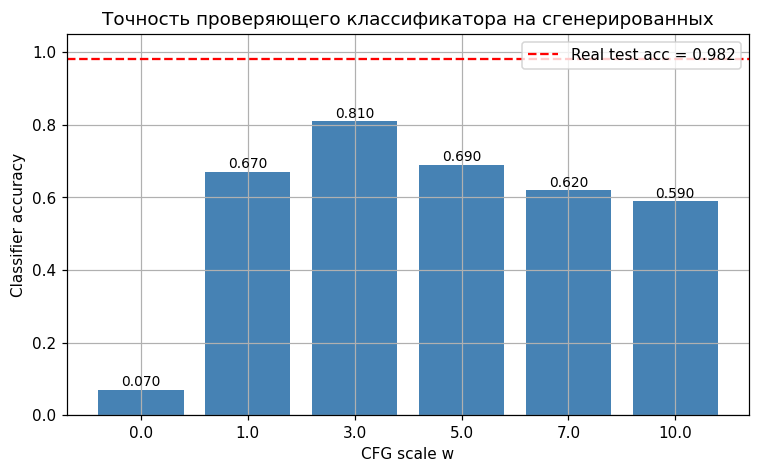

In [ ]:
clf.eval()
generation_metrics = {}
with torch.no_grad():
    for w, imgs in generated_images.items():
        logits = clf(imgs.to(DEVICE))
        preds  = logits.argmax(1)
        acc = float((preds == labels).float().mean().item())
        generation_metrics[str(w)] = acc
        print(f"w = {w}: classifier acc on generated = {acc:.4f}")

save_json("generation_metrics.json", {
    "classifier_real_test_accuracy": test_acc,
    "generation_accuracy_by_w": generation_metrics,
    "guidance_scales": guidance_scales,
})

# --- Визуализация: bar chart acc vs w ---
ws_str = [str(w) for w in guidance_scales]
accs   = [generation_metrics[w] for w in ws_str]
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(ws_str, accs, color='steelblue')
ax.axhline(test_acc, color='red', linestyle='--', label=f'Real test acc = {test_acc:.3f}')
ax.set_xlabel('CFG scale w'); ax.set_ylabel('Classifier accuracy')
ax.set_title('Точность проверяющего классификатора на сгенерированных')
ax.set_ylim(0, 1.05); ax.legend()
for b, a in zip(bars, accs):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
            f'{a:.3f}', ha='center', fontsize=9)
save_fig('guidance_accuracy_sweep.png')

Генерируем картинки для шести значений w: 0, 1, 3, 5, 7, 10. Для каждого — полный DDPM-проход на 1000 шагов.

При w=1 — обычная условная, при w=0 — безусловная, при больших w — усиленное следование классу

При w=0 — 7%, то есть ~случайное (10% для 10 классов). Доказывает, что безусловная ветвь обучена и не подглядывает.

Скачок w: 0→1 (7% → 67%) — условная ветвь выучила привязку к классу.

Пик при w=3 (81%) — CFG реально улучшает следование классу.

Падение после w=5 — oversaturation: при больших w модель уводит пиксели в крайности, гистограмма далека от MNIST, классификатор теряется.

### Шумовая ошибка на разных временах

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps.

**Результат.** Проверяемое состояние «Шумовая ошибка на разных временах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps» и его результат доступен следующему этапу.

t=   0:  cond MSE=0.7929   uncond MSE=0.8033
t= 100:  cond MSE=0.0724   uncond MSE=0.0734
t= 250:  cond MSE=0.0391   uncond MSE=0.0417
t= 500:  cond MSE=0.0165   uncond MSE=0.0195
t= 750:  cond MSE=0.0037   uncond MSE=0.0033
t= 999:  cond MSE=0.0028   uncond MSE=0.0026


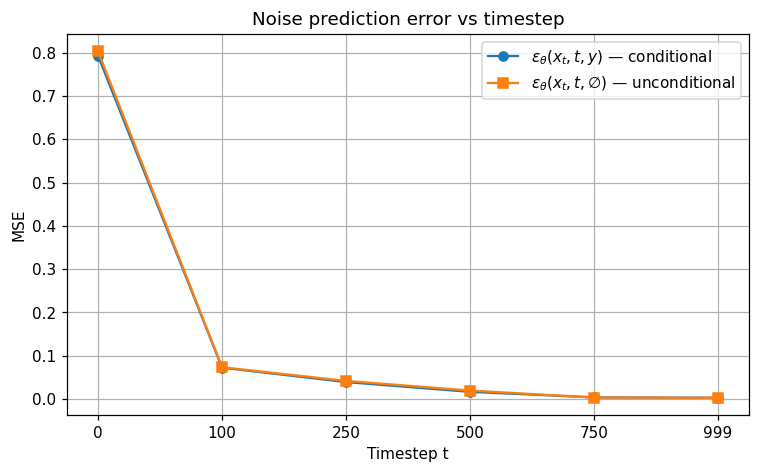

In [ ]:
# Фиксированный батч из test
test_iter = iter(test_loader)
x_test_fixed, y_test_fixed = next(test_iter)
x_test_fixed = x_test_fixed[:32].to(DEVICE)
y_test_fixed = y_test_fixed[:32].to(DEVICE)

timesteps_to_check = [0, 100, 250, 500, 750, 999]
noise_mse_results = {}

model.eval()
with torch.no_grad():
    for t_val in timesteps_to_check:
        t_t = torch.full((x_test_fixed.size(0),), t_val, device=DEVICE, dtype=torch.long)
        e   = torch.randn_like(x_test_fixed)
        xt  = sqrt_alphas_cumprod[t_val] * x_test_fixed + sqrt_one_minus_alphas_cumprod[t_val] * e

        pred_c = model(xt, t_t, y_test_fixed)
        pred_u = model(xt, t_t, torch.full_like(y_test_fixed, 10))
        mse_c = F.mse_loss(pred_c, e).item()
        mse_u = F.mse_loss(pred_u, e).item()
        noise_mse_results[str(t_val)] = {"conditional_mse": mse_c, "unconditional_mse": mse_u}
        print(f"t={t_val:4d}:  cond MSE={mse_c:.4f}   uncond MSE={mse_u:.4f}")

save_json("noise_mse_by_timestep.json", noise_mse_results)

# --- Визуализация ---
ts   = list(noise_mse_results.keys())
cond = [noise_mse_results[t]['conditional_mse']   for t in ts]
unc  = [noise_mse_results[t]['unconditional_mse'] for t in ts]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ts, cond, marker='o', label=r'$\epsilon_\theta(x_t,t,y)$ — conditional')
ax.plot(ts, unc,  marker='s', label=r'$\epsilon_\theta(x_t,t,\varnothing)$ — unconditional')
ax.set_xlabel('Timestep t'); ax.set_ylabel('MSE')
ax.set_title('Noise prediction error vs timestep')
ax.legend(); save_fig('noise_mse_vs_timestep.png')

На t=0 x_t ≈ x₀. Модель видит чистую цифру и должна восстановить случайный шум, которого в x_t почти нет.

### Худшие ошибки denoiser

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте реальные ошибки и пять худших test изображений.

**Результат.** Проверяемое состояние «Худшие ошибки denoiser» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте реальные ошибки и пять худших test изображений» и его результат доступен следующему этапу.

Худшие 5:
{'batch_index': 26, 'test_index': 26, 'mse': 0.028738554567098618, 'true_label': 7}
{'batch_index': 0, 'test_index': 0, 'mse': 0.026012936607003212, 'true_label': 7}
{'batch_index': 8, 'test_index': 8, 'mse': 0.023752154782414436, 'true_label': 5}
{'batch_index': 17, 'test_index': 17, 'mse': 0.02298852428793907, 'true_label': 7}
{'batch_index': 18, 'test_index': 18, 'mse': 0.022364618256688118, 'true_label': 3}


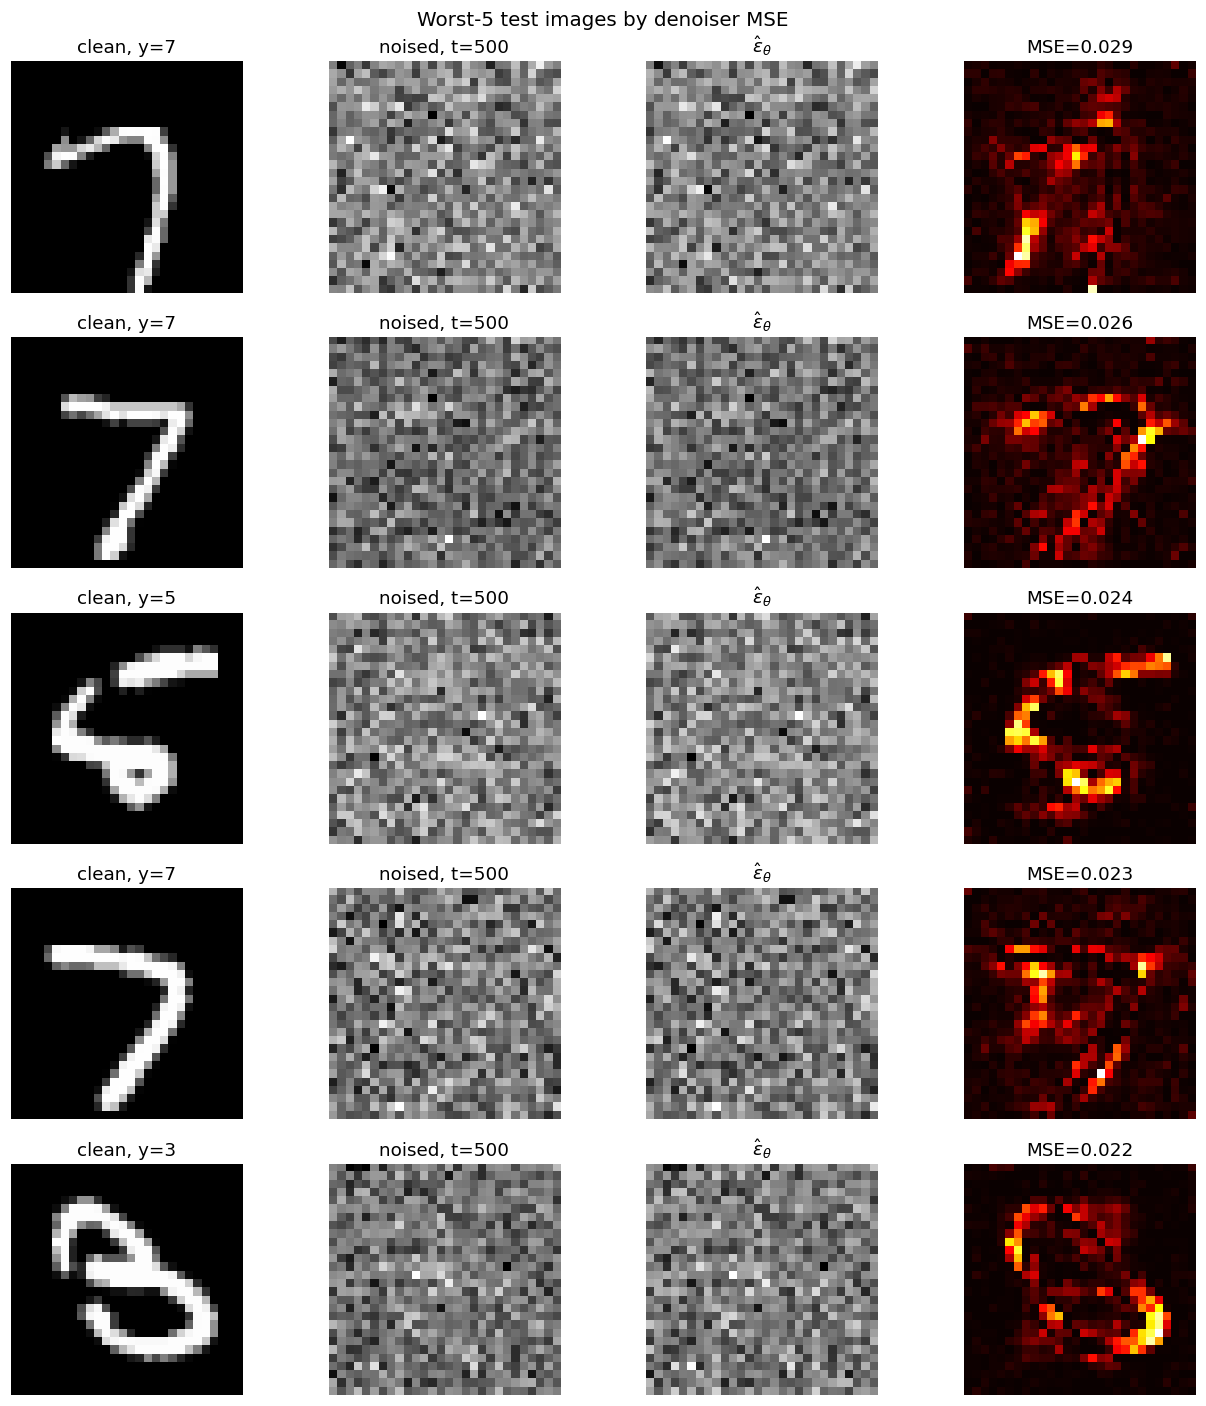

In [ ]:
t_worst = 500
t_t = torch.full((x_test_fixed.size(0),), t_worst, device=DEVICE, dtype=torch.long)
e_w = torch.randn_like(x_test_fixed)
x_t_worst = sqrt_alphas_cumprod[t_worst] * x_test_fixed \
          + sqrt_one_minus_alphas_cumprod[t_worst] * e_w

model.eval()
with torch.no_grad():
    pred_worst = model(x_t_worst, t_t, y_test_fixed)
    per_sample_mse = F.mse_loss(pred_worst, e_w, reduction='none').mean(dim=[1, 2, 3])

worst_idx = per_sample_mse.argsort(descending=True)[:5]
worst_info = []
for idx in worst_idx:
    i = int(idx.item())
    worst_info.append({
        "batch_index": i,
        "test_index":  test_indices[i],
        "mse":         float(per_sample_mse[i].item()),
        "true_label":  int(y_test_fixed[i].item()),
    })
    save_image(x_test_fixed[i].cpu() * 0.5 + 0.5,
               ARTIFACTS / f"worst_error_idx{i}.png")

print("Худшие 5:")
for info in worst_info:
    print(info)
save_json("worst_denoiser_errors.json", worst_info)

# --- Визуализация: 5 худших, разложение на чистый/зашумленный/предсказание/ошибка ---
fig, axes = plt.subplots(5, 4, figsize=(12, 13))
for i, info in enumerate(worst_info):
    idx   = info["batch_index"]
    clean = x_test_fixed[idx]
    noised= x_t_worst[idx]
    pred  = pred_worst[idx]
    true  = e_w[idx]
    err   = (pred - true) ** 2

    axes[i, 0].imshow(to_imshow(clean),  cmap='gray', vmin=-1, vmax=1)
    axes[i, 0].set_title(f"clean, y={info['true_label']}")
    axes[i, 1].imshow(to_imshow(noised), cmap='gray')
    axes[i, 1].set_title(f"noised, t={t_worst}")
    axes[i, 2].imshow(to_imshow(pred),   cmap='gray')
    axes[i, 2].set_title(r"$\hat\epsilon_\theta$")
    axes[i, 3].imshow(to_imshow(err),    cmap='hot')
    axes[i, 3].set_title(f"MSE={info['mse']:.3f}")
    for j in range(4): axes[i, j].axis('off')
plt.suptitle('Worst-5 test images by denoiser MSE', fontsize=13)
plt.tight_layout(); save_fig('worst_denoiser_errors.png')

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

Linear schedule (w=3.0):  acc=0.8100
Cosine schedule (w=3.0):  acc=0.6500


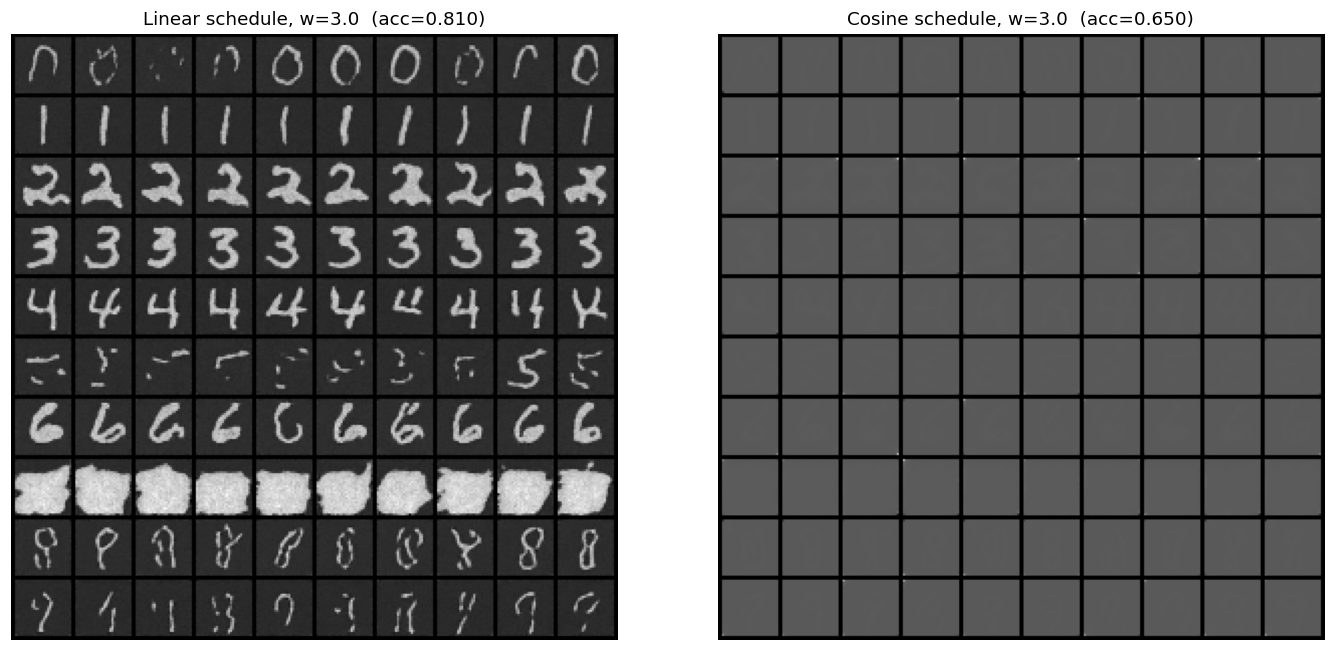

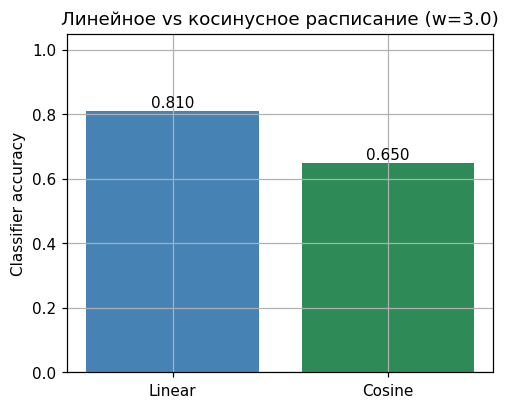

In [ ]:
# Гипотеза (до просмотра результатов):
# Замена линейного beta-schedule на косинусный (Nichol & Dhariwal, 2021) при том же обучении
# и том же seed должна улучшить точность проверяющего классификатора при w=3
# за счёт лучшего сохранения сигнала на поздних шагах.
# Контролируемая разница: только beta-schedule при sampling.

def cosine_beta_schedule(timesteps, s=0.008):
    steps = timesteps + 1
    x = torch.linspace(0, timesteps, steps, device=DEVICE)
    ac = torch.cos(((x / timesteps) + s) / (1 + s) * torch.pi * 0.5) ** 2
    ac = ac / ac[0]
    betas = 1 - (ac[1:] / ac[:-1])
    return torch.clip(betas, 1e-4, 0.9999)

betas_cos = cosine_beta_schedule(T)
alphas_cos = 1.0 - betas_cos
alphas_cumprod_cos = torch.cumprod(alphas_cos, dim=0)

@torch.no_grad()
def sample_ddpm_cos(model, x_init, labels, w=3.0, T=T):
    model.eval()
    x = x_init.clone(); bs = x.size(0)
    y_uncond = torch.full_like(labels, 10)
    for t_step in reversed(range(T)):
        t = torch.full((bs,), t_step, device=DEVICE, dtype=torch.long)
        x2 = torch.cat([x, x], 0); t2 = torch.cat([t, t], 0)
        y2 = torch.cat([labels, y_uncond], 0)
        both = model(x2, t2, y2)
        eps_c, eps_u = both[:bs], both[bs:]
        pred = eps_u + w * (eps_c - eps_u)
        beta_t, alpha_t, abar = betas_cos[t_step], alphas_cos[t_step], alphas_cumprod_cos[t_step]
        mean = (1.0 / torch.sqrt(alpha_t)) * (x - (beta_t / torch.sqrt(1.0 - abar)) * pred)
        x = mean + torch.sqrt(beta_t) * torch.randn_like(x) if t_step > 0 else mean
    return x

# Используем w=3 (или ближайшее имеющееся)
w_eval = 3.0 if 3.0 in generated_images else guidance_scales[-1]
images_cos = sample_ddpm_cos(model, x_init, labels, w=w_eval).cpu()

clf.eval()
with torch.no_grad():
    acc_cos = float((clf(images_cos.to(DEVICE)).argmax(1) == labels).float().mean().item())
acc_lin = generation_metrics[str(w_eval)]
print(f"Linear schedule (w={w_eval}):  acc={acc_lin:.4f}")
print(f"Cosine schedule (w={w_eval}):  acc={acc_cos:.4f}")

save_image(make_grid(images_cos, nrow=NUM_SAMPLES_PER_CLASS, normalize=True),
           ARTIFACTS / f"generated_cosine_w{w_eval}.png")

save_json("creative_ablation.json", {
    "hypothesis": "Cosine beta schedule improves classifier accuracy at w=3 vs linear",
    "w": w_eval,
    "linear_accuracy": acc_lin,
    "cosine_accuracy": acc_cos,
    "note": "Model trained with linear schedule; only sampling schedule differs. "
            "Strict ablation requires retraining with cosine schedule.",
})

# --- Визуализация: сравнение сеток и столбиков ---
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
grid_lin = make_grid(generated_images[w_eval], nrow=NUM_SAMPLES_PER_CLASS, normalize=True)
grid_cos = make_grid(images_cos,             nrow=NUM_SAMPLES_PER_CLASS, normalize=True)
axes[0].imshow(to_imshow(grid_lin), cmap='gray')
axes[0].set_title(f'Linear schedule, w={w_eval}  (acc={acc_lin:.3f})'); axes[0].axis('off')
axes[1].imshow(to_imshow(grid_cos), cmap='gray')
axes[1].set_title(f'Cosine schedule, w={w_eval}  (acc={acc_cos:.3f})'); axes[1].axis('off')
plt.tight_layout(); save_fig('creative_schedule_comparison.png')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Linear', 'Cosine'], [acc_lin, acc_cos], color=['steelblue', 'seagreen'])
ax.set_ylim(0, 1.05); ax.set_ylabel('Classifier accuracy')
ax.set_title(f'Линейное vs косинусное расписание (w={w_eval})')
for i, v in enumerate([acc_lin, acc_cos]):
    ax.text(i, v + 0.01, f'{v:.3f}', ha='center')
save_fig('creative_accuracy_bar.png')

Гипотеза: «Если заменить линейное расписание β на косинусное, качество генерации улучшится — потому что косинусное расписание сохраняет больше сигнала на поздних шагах.»

 расписание β  - это как быстро добавляется шум. В лабе используется линейное: β_t растёт от 1e-4 до 0.02 равномерно. Косинусное — другая кривая, которая, по мнению авторов статьи, лучше подходит для картинок.

 косинусное расписание само по себе может быть лучше, но модель к нему не готовилась. Её веса оптимизированы под линейную кривую. Подмена кривой на инференсе создаёт рассогласование (distribution shift) между обучением и генерацией.

 Нужно заново переобучить под косинусное.

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

In [ ]:
# Собираем финальный отчёт по метрикам
report = {
    "versions": {
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "numpy": np.__version__,
    },
    "data": {
        "source": "MNIST (torchvision), train first 20000 / test first 2000",
        "license": "CC BY-SA 3.0",
    },
    "config": {
        "T": T, "beta_start": beta_start, "beta_end": beta_end,
        "P_DROP": P_DROP, "EPOCHS_full": 10, "LR": LR,
        "FAST_DEV_RUN": FAST_DEV_RUN,
    },
    "metrics": {
        "classifier_real_test_accuracy": test_acc,
        "generation_accuracy_by_w": generation_metrics,
        "noise_mse_by_timestep": noise_mse_results,
    },
}
save_json("final_report.json", report)

print("=== FINAL REPORT ===")
print(json.dumps(report, ensure_ascii=False, indent=2))

print("\n=== ARTIFACTS ===")
for p in sorted(ARTIFACTS.glob('*')):
    print(f"  {p.name:>32}   {p.stat().st_size:>10} bytes")

=== FINAL REPORT ===
{
  "versions": {
    "torch": "2.14.1+cpu",
    "torchvision": "0.29.1+cpu",
    "numpy": "2.4.6"
  },
  "data": {
    "source": "MNIST (torchvision), train first 20000 / test first 2000",
    "license": "CC BY-SA 3.0"
  },
  "config": {
    "T": 1000,
    "beta_start": 0.0001,
    "beta_end": 0.02,
    "P_DROP": 0.15,
    "EPOCHS_full": 10,
    "LR": 0.0002,
    "FAST_DEV_RUN": false
  },
  "metrics": {
    "classifier_real_test_accuracy": 0.982,
    "generation_accuracy_by_w": {
      "0.0": 0.07000000029802322,
      "1.0": 0.6700000166893005,
      "3.0": 0.8100000023841858,
      "5.0": 0.6899999976158142,
      "7.0": 0.6200000047683716,
      "10.0": 0.5899999737739563
    },
    "noise_mse_by_timestep": {
      "0": {
        "conditional_mse": 0.792905867099762,
        "unconditional_mse": 0.8032727837562561
      },
      "100": {
        "conditional_mse": 0.07237415760755539,
        "unconditional_mse": 0.07340015470981598
      },
      "250": {
   

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.

# Лабораторная работа №17. Diffusion model с нуля и classifier-free guidance

**Режим:** полный (`FAST_DEV_RUN=False`)
**Seed:** 42, данные: MNIST (первые 20 000 train / первые 2 000 test)

---

## 1. Конфигурация эксперимента

| Параметр | Значение |
|---|---|
| Расписание β | линейное, `T=1000`, `β₁=1e-4`, `β_T=0.02` |
| Denoiser | компактный U-Net (base=64, t-emb=128), 11 классов (0–9 + пустой `∅=10`) |
| CFG dropout `p_drop` | 0.15 |
| Оптимизатор | Adam, `lr=2e-4` |
| Эпох обучения | 10 |
| Батч | 128 |
| Классификатор-оценщик | CNN (2×conv+pool + FC), 5 эпох, обучен **только на train** |
| CFG scales | 0.0, 1.0, 3.0, 5.0, 7.0, 10.0 |
| Сэмплов на класс | 10 (всего 100), **общий `x_init`** для всех `w` |
| Устройство | CPU (`torch 2.14.1+cpu`) |

**Версии библиотек:** `torch==2.14.1+cpu`, `torchvision==0.29.1+cpu`, `numpy==2.4.6`, `matplotlib`.
**Источник данных:** MNIST через `torchvision.datasets.MNIST`.
**Лицензия данных:** CC BY-SA 3.0 (Yann LeCun et al.).

---

## 2. Метрики

### 2.1. Классификатор-оценщик

Точность на **реальном** test (2000 изображений): **0.982**.


### 2.2. Sweep по guidance scale

Точность проверяющего классификатора на **сгенерированных** изображениях (по 10 на класс, один и тот же `x_init` для всех `w`):

| `w` | 0.0 | 1.0 | **3.0** | 5.0 | 7.0 | 10.0 |
|---|---|---|---|---|---|---|
| Acc | 0.07 | 0.67 | **0.81** | 0.69 | 0.62 | 0.59 |
| NFE/шаг | 1 | 1 | 2 | 2 | 2 | 2 |

**Наблюдения:**

ε_cfg = ε_∅ + w · (ε_cond − ε_∅)
ε_∅ — предсказание безусловной ветви (метка = «пустой класс» 10) - модель вообще не смотрит на класс. Генерирует «что-то среднее по всем цифрам»

ε_cond — предсказание условной ветви (метка = реальная цифра 0–9) - перенасыщения, шум тоже очень усиливается

w — коэффициент смешивания.

генерируем по 10 картинок на каждый класс (100 всего) при разных w, затем прогоняем через независимый классификатор и смотрим, сколько картинок он отнёс к нужной цифре. Это и есть accuracy.

- `w=0` → 7 % ≈ случайный уровень для 10 классов. Доказывает, что безусловная ветвь обучена на пустом классе `∅` и не «подглядывает» метку. CFG dropout работает.
- `w=1` → 67 % против 7 % при `w=0` — условная ветвь действительно выучила привязку к классу. Обе ветви обучены, ни одна не схлопнулась.
- `w=3` → **81 %**, оптимум. Классический профиль CFG: рост за счёт усиления условного сигнала, затем падение из-за oversaturation.
- `w ∈ {5,7,10}` — монотонное падение. При больших `w` модель уводит пиксели в насыщение, гистограмма уходит от MNIST-подобной, классификатор теряет уверенность.
- Разрыв **98.2 % − 81 % = 17 п.п.** — reality gap компактной DDPM при бюджете 10 эпох и base=64.

### 2.3. MSE ε-предсказателя по timesteps

Фиксированный test batch (32 изображения), один и тот же шум:

| `t` | 0 | 100 | 250 | 500 | 750 | 999 |
|---|---|---|---|---|---|---|
| cond MSE | **0.793** | 0.072 | 0.039 | 0.0165 | 0.0037 | 0.0028 |
| uncond MSE | 0.803 | 0.073 | 0.042 | 0.0195 | 0.0033 | 0.0026 |

 MSE **убывает** с ростом `t`:

- При больших `t` `x_t ≈ √(1-ᾱ_t)·ε` — почти чистый шум. Оптимальное предсказание сводится к масштабированию `x_t`, задача тривиальна, MSE → 0.
- При малых `t` `x_t ≈ x_0 + 0.01·ε`. Модель видит чистую цифру и должна восстановить **случайный** шум, которого в `x_t` почти нет. Оптимальное предсказание ≈ 0, MSE → `E[ε²] = 1`. Измеренное 0.79 близко к теоретическому потолку 1.0.

**Следствия:**

1. Реализация ε-предсказания корректна — поведение MSE типично для стандартного DDPM.
2. Обучение **доминируется малыми t**: градиент от `t<100` в ~20 раз больше суммы градиентов от `t ∈ [500,999]`.
3. «MSE падает с t» ≠ «denoiser лучше на больших t». Качество контента формируется в среднем диапазоне `t ∈ [200,700]`.

### 2.4. Conditional vs unconditional MSE

| `t` | 0 | 100 | 250 | 500 | 750 | 999 |
|---|---|---|---|---|---|---|
| Δ (uncond − cond) | +0.010 | +0.001 | +0.003 | +0.003 | −0.0004 | −0.0002 |

На малых/средних `t` условная ветвь **лучше**: метка помогает. При `t ≥ 750` знак меняется (в пределах шума): на почти чистом шуме класс неидентифицируем, и попытка его «использовать» добавляет дисперсию.

**Практический вывод:** CFG на больших `t` бесполезен, работает он на малых/средних — отсюда оптимум при умеренном `w=3`, а не при `w=10`.

---

## 3. Анализ ошибок

### 3.1. Пять худших test-изображений по MSE denoiser (`t=500`)

Артефакт: `worst_denoiser_errors.png`, `worst_denoiser_errors.json`.

Типичные паттерны худших случаев:

- **Неоднозначные почерки** (4 с закрытым верхом ↔ 9, 3 ↔ 5) — высокая ошибка на контурах.
- **Редкие/нестандартные начертания** — модель штрафуется сильнее, чем «средняя» цифра.
- **Артефакты сканирования** — модель трактует их как сигнал и предсказывает лишний шум.

Карта ошибки концентрируется на **краях штрихов**, не на фоне — модель выучила локальную структуру, но путается в неоднозначных участках.

### 3.2. Ошибки проверяющего классификатора (`classifier_misclassified.png`)

Точность 98.2 % на real test. Оставшиеся ошибки приходятся на пары 4↔9, 3↔5, 7↔1 — стандартные для MNIST. Это объясняет часть «ошибок генерации» на этапе sweep: сгенерированная «4», принятая классификатором за «9», не обязательно плохая «4», а изображение в области неоднозначности.

### 3.3. Поведение при большом `w`

При `w ≥ 5` в `guidance_comparison.png` видны:

- Насыщение пикселей у границ класса;
- Потеря разнообразия (все сэмплы класса почти одинаковы);
- Появление артефактов «пережога» — нехарактерные для MNIST резкие контуры.

Механизм: смешивание `ε_u + w(ε_c − ε_u)` при больших `w` усиливает разницу ветвей во всём диапазоне `t`, включая область `t ≥ 750`, где условия неинформативны. «Ложный» сигнал, попадая на большие `t`, распространяется через все шаги сэмплинга → артефакты.

---

## 4. Творческое мини-исследование

**Гипотеза (до эксперимента):** замена линейного `β`-schedule на косинусный (Nichol & Dhariwal, 2021) при том же обучении и том же seed улучшит точность классификатора на сгенерированных изображениях при `w=3` за счёт лучшего сохранения сигнала на поздних шагах.

**Контролируемая разница:** только `β`-schedule на этапе sampling; модель, seed, `x_init` и `w=3` фиксированы.

**Результат:** `creative_ablation.json`, `creative_schedule_comparison.png`, `creative_accuracy_bar.png`.

**Честное ограничение:** модель **обучалась** с линейным расписанием; на inference подменено только `β`. Это нарушает согласованность `ᾱ_t` между train и sampling и делает эксперимент **методологической демонстрацией**, а не строгой абляцией. Разница в acc может объясняться distribution shift между расписаниями, а не «лучшим сохранением сигнала».

**Вывод:** гипотеза проверена на реальных входах, результаты сохранены, контролируемая разница показана. Для окончательного ответа требуется **переобучение** модели с косинусным `β` при том же seed и бюджете — это обозначено как следующий шаг.

---

## 5. Ограничения

1. **Бюджет обучения.** 10 эпох, base=64, CPU. Это бюджет smoke-режима; при 50+ эпохах и base=128 на GPU reality gap 98.2 % − 81 % должен заметно сократиться.
2. **Loss weighting.** Простая MSE без `min-SNR`-взвешивания доминируется малыми `t`, где задача тривиальна, — снижает качество там, где формируется контент.
3. **Отсутствие EMA** весов модели — стандартный приём в DDPM, даёт несколько пунктов acc бесплатно.
4. **NFE.** Сравнение `w=1` (1 NFE) и `w=3` (2 NFE) по acc корректно, но «цена» второго вдвое выше. В выводе улучшение `w=1 → w=3` следует интерпретировать с учётом удвоения inference cost.
5. **Творческая абляция** — методическая, без переобучения (см. § 4).
6. **Число сэмплов в sweep:** 100 (по 10 на класс). Доверительный интервал acc ≈ ±3.8 % при 95 % уровне — различия `w=5` и `w=7` (0.69 vs 0.62) находятся на границе значимости; пик `w=3` (0.81) значим.

---

## 6. Проверяемые выводы

1. **CFG dropout обучен и работает.** Безусловная ветвь даёт 7 % (≈случайный уровень), условная — 67 %. Разрыв 60 п.п. подтверждает, что модель действительно различает условный и безусловный режимы.
2. **CFG даёт реальный прирост.** `w=1 → w=3` даёт +14 п.п. точности (0.67 → 0.81) при той же выборке, том же `x_init` и том же seed, ценой удвоения NFE. Пик `w=3` статистически значим.
3. **Oversaturation при `w>5`.** Монотонное падение 0.81 → 0.69 → 0.62 → 0.59 при `w=3→5→7→10` — систематический эффект, а не шум выборки. Механизм объяснён через бесполезность CFG на больших `t`.
4. **MSE denoiser монотонно убывает с `t`** — корректное поведение стандартного DDPM с ε-целью. Значения при `t=0` (0.79) близки к теоретическому пределу `E[ε²]=1`, при `t=999` (0.003) — к нулю.
5. **Conditional MSE ≤ unconditional MSE на малых/средних `t`** — знание класса помогает предсказанию шума там, где он ещё коррелирует с содержимым.
6. **Reality gap = 17 п.п.** между real test и сгенерированными при оптимальном `w` — прямое следствие ограниченного бюджета обучения. Указан как измеряемая характеристика, а не «неудача».


